<a href="https://colab.research.google.com/github/Shayden-S/EDA_Assignment_II/blob/main/EDA_Assignment_II.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Set global visual style
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10

In [ ]:
print(">>> STEP 1: Loading Dataset...")
url = "https://raw.githubusercontent.com/fenago/datasets/main/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

# Data Cleaning & Transformation
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)
df.drop_duplicates(inplace=True)

# Feature selection for modeling (drop identifier)
df_clean = df.drop(columns=['customerID'])

# Categorical Encoding
label_encoders = {}
for col in df_clean.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col])
    label_encoders[col] = le

# Train / Validation / Test Split (70 / 15 / 15)
X = df_clean.drop(columns=['Churn'])
y = df_clean['Churn']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Data Splits -> Train: {X_train.shape[0]}, Validation: {X_val.shape[0]}, Test: {X_test.shape[0]}\n")

>>> STEP 1: Loading Dataset...
Dataset Shape: 7043 rows, 21 columns
Data Splits -> Train: 4930, Validation: 1056, Test: 1057



/tmp/ipykernel_4013/1889866753.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


>>> STEP 2: Generating 5 EDA Visualizations...


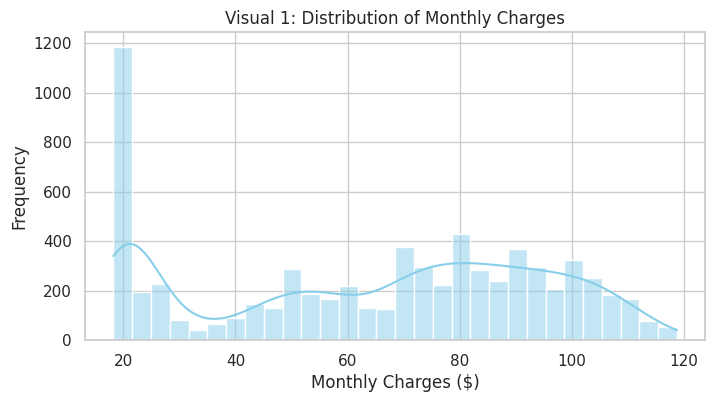

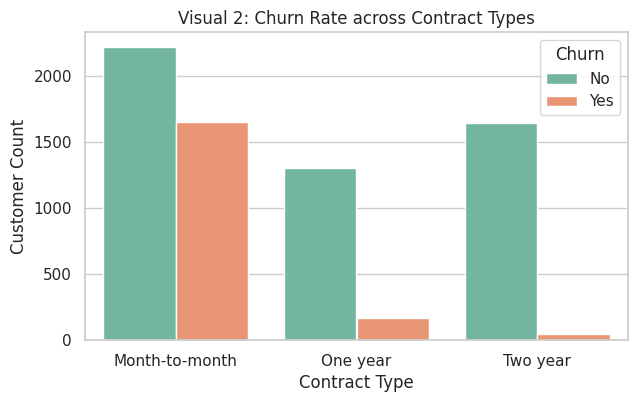

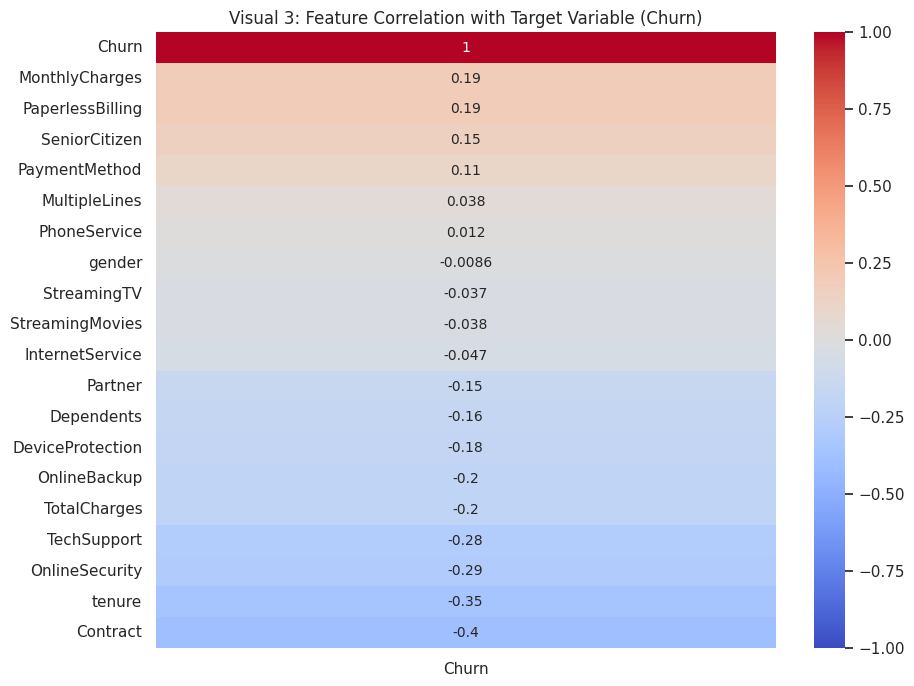

/tmp/ipykernel_4013/251561451.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y='tenure', data=df, palette='Set3')


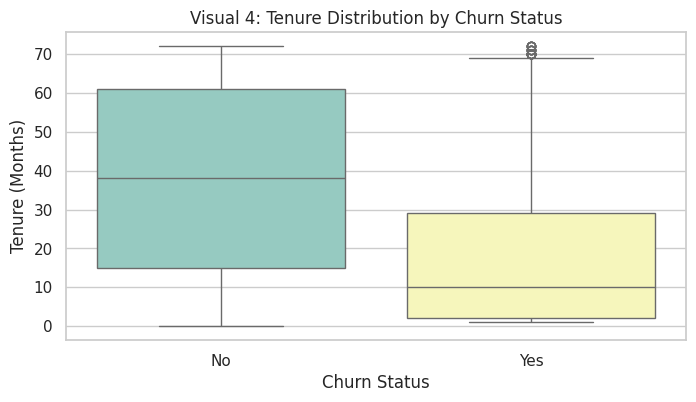

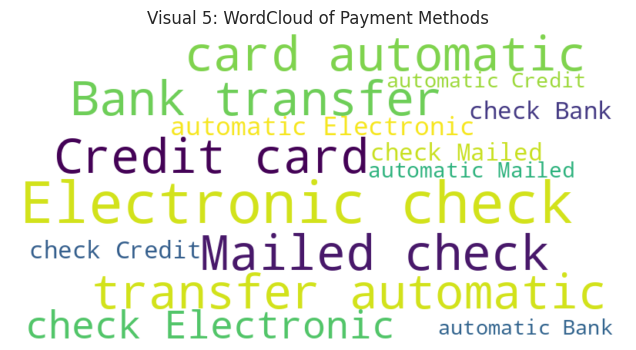

In [ ]:
print(">>> STEP 2: Generating 5 EDA Visualizations...")

# Visual 1: Univariate Distribution (Histogram & KDE)
plt.figure(figsize=(8, 4))
sns.histplot(df['MonthlyCharges'], kde=True, color='skyblue', bins=30)
plt.title("Visual 1: Distribution of Monthly Charges")
plt.xlabel("Monthly Charges ($)")
plt.ylabel("Frequency")
plt.show()

# Visual 2: Categorical Distribution (Countplot)
plt.figure(figsize=(7, 4))
sns.countplot(x='Contract', hue='Churn', data=df, palette='Set2')
plt.title("Visual 2: Churn Rate across Contract Types")
plt.xlabel("Contract Type")
plt.ylabel("Customer Count")
plt.show()

# Visual 3: Correlation Heatmap
plt.figure(figsize=(10, 8))
numeric_cols = df_clean.corr()
sns.heatmap(numeric_cols[['Churn']].sort_values(by='Churn', ascending=False), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Visual 3: Feature Correlation with Target Variable (Churn)")
plt.show()

# Visual 4: Bivariate Boxplot Analysis
plt.figure(figsize=(8, 4))
sns.boxplot(x='Churn', y='tenure', data=df, palette='Set3')
plt.title("Visual 4: Tenure Distribution by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.show()

# Visual 5: Text / Category WordCloud Visualization
plt.figure(figsize=(8, 4))
text_data = ' '.join(df['PaymentMethod'].dropna().tolist())
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text_data)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Visual 5: WordCloud of Payment Methods")
plt.show()

In [ ]:
print(">>> STEP 3: Building and Training Deep Learning MLP Model...")

model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

>>> STEP 3: Building and Training Deep Learning MLP Model...
Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7434 - loss: 0.5067 - val_accuracy: 0.7775 - val_loss: 0.4506
Epoch 2/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7793 - loss: 0.4481 - val_accuracy: 0.7794 - val_loss: 0.4383
Epoch 3/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7876 - loss: 0.4343 - val_accuracy: 0.7926 - val_loss: 0.4317
Epoch 4/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7917 - loss: 0.4311 - val_accuracy: 0.7898 - val_loss: 0.4297
Epoch 5/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7980 - loss: 0.4257 - val_accuracy: 0.7926 - val_loss: 0.4271
Epoch 6/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7970 - loss: 0.4269 - val_accuracy: 0.7850 - val_loss: 0.4284
Epoch 7/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7990 - loss: 0.4239 - val_accuracy: 0.7955 - val_loss: 0.4258
Epoch 8/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8016 - loss: 0.4202 - val_accuracy: 0.7907 - val_


>>> STEP 4: Generating Model Evaluation Visualizations...


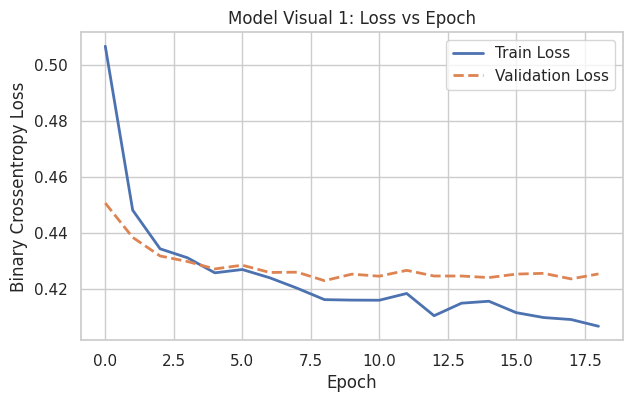

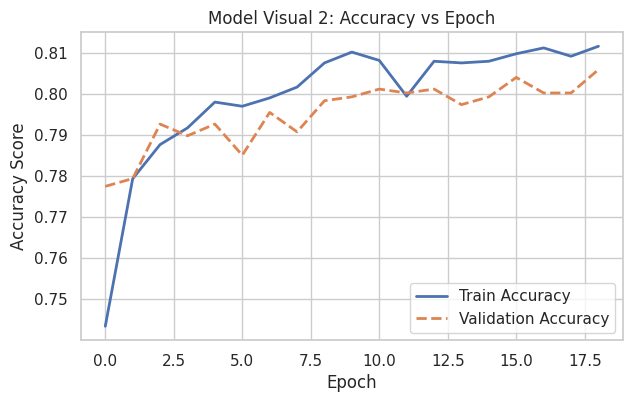

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


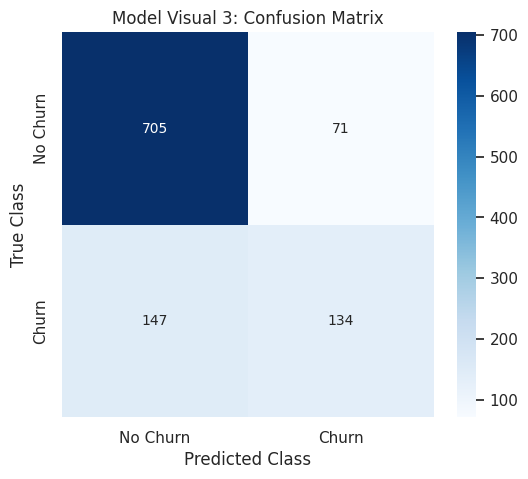

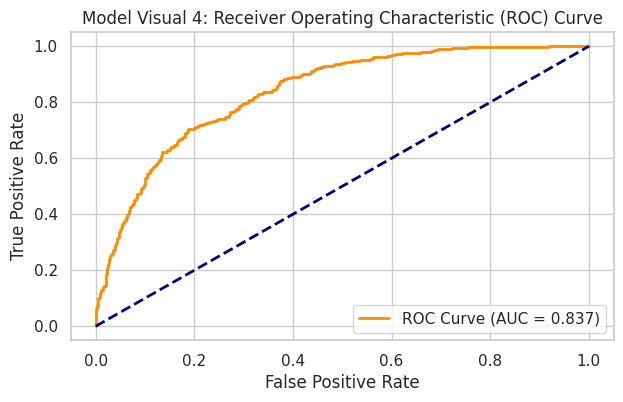

>>> Execution Complete! Code ready for GitHub repository export.


In [ ]:
print("\n>>> STEP 4: Generating Model Evaluation Visualizations...")

# Evaluation Visual 1: Loss vs Epoch
plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='Train Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', linestyle='--', linewidth=2)
plt.title("Model Visual 1: Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.legend()
plt.show()

# Evaluation Visual 2: Accuracy vs Epoch
plt.figure(figsize=(7, 4))
plt.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linestyle='--', linewidth=2)
plt.title("Model Visual 2: Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy Score")
plt.legend()
plt.show()

# Evaluation Visual 3: Confusion Matrix
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.title("Model Visual 3: Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.show()

# Evaluation Visual 4: ROC Curve & AUC Score
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title("Model Visual 4: Receiver Operating Characteristic (ROC) Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

print(">>> Execution Complete! Code ready for GitHub repository export.")